# Sesión 14 · Medidas de dispersión
**Introducción a la Ingeniería en Ciencia de Datos · 2026-3C · Universidad del Magdalena**

Caso: Bienestar Universitario debe escoger el operador de la ruta de bus. Prueba piloto de **10 viajes por empresa** (A y B), mismo recorrido y misma hora de salida (6:30 a. m.). Una sola variable: el **tiempo de recorrido** en minutos (`ruta_piloto.csv`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

df = pd.read_csv('ruta_piloto.csv')
tabla = df.pivot(index='dia', columns='empresa', values='tiempo_min')
tabla

empresa,A,B
dia,,
1,25,36
2,23,18
3,30,42
4,22,27
5,26,21
6,28,46
7,69,19
8,24,33
9,23,22


## Enganche: empate en la media

In [2]:
t = df.groupby('empresa')['tiempo_min']
t.agg(['count', 'mean', 'median'])

,count,mean,median
empresa,,,
A,10,30.0,25.5
B,10,30.0,30.0


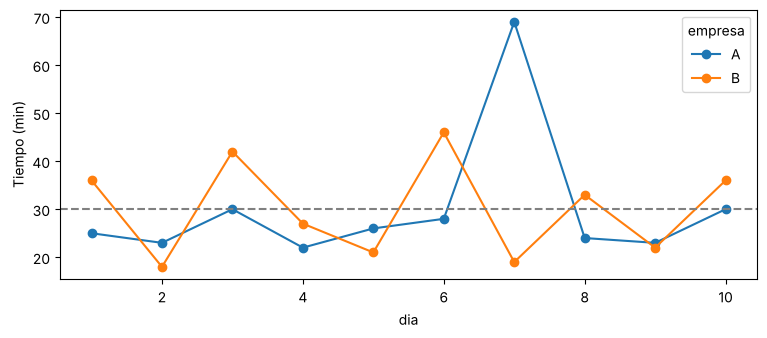

In [3]:
# Gráfico día a día (serie temporal)
ax = tabla.plot(marker='o', figsize=(9, 3.5))
ax.axhline(30, ls='--', color='gray')
ax.set_ylabel('Tiempo (min)')
plt.show()

## Bloque 1 · Rango

In [4]:
rango = t.max() - t.min()
print(rango)
A = tabla['A']; B = tabla['B']
print('Rango de A sin el día 7:', A.drop(7).max() - A.drop(7).min())

empresa
A    47
B    28
Name: tiempo_min, dtype: int64
Rango de A sin el día 7: 8


## Bloque 2 · Varianza, desviación estándar y CV

In [5]:
desv = B - B.mean()
pd.DataFrame({'x': B, 'x - media': desv, '(x - media)^2': desv**2}).sort_values('x')

,x,x - media,(x - media)^2
dia,,,
2,18,-12.0,144.0
7,19,-11.0,121.0
5,21,-9.0,81.0
9,22,-8.0,64.0
4,27,-3.0,9.0
8,33,3.0,9.0
10,36,6.0,36.0
1,36,6.0,36.0
3,42,12.0,144.0


In [6]:
for nombre, x in [('A', A), ('B', B)]:
    ss = ((x - x.mean())**2).sum()
    print(f'{nombre}: SC = {ss:.0f}  s2 = {x.var():.1f}  s = {x.std():.2f}  sigma2 = {x.var(ddof=0):.1f}  sigma = {x.std(ddof=0):.2f}')

A: SC = 1764  s2 = 196.0  s = 14.00  sigma2 = 176.4  sigma = 13.28
B: SC = 900  s2 = 100.0  s = 10.00  sigma2 = 90.0  sigma = 9.49


In [7]:
# ¿Cuánto pesa el día 7 en la suma de cuadrados de A?
sc = (A - A.mean())**2
print('Aporte del día 7:', round(sc[7] / sc.sum(), 3))
print('s de A sin el día 7:', round(A.drop(7).std(), 2), '| media sin el día 7:', round(A.drop(7).mean(), 2))

Aporte del día 7: 0.862
s de A sin el día 7: 3.04 | media sin el día 7: 25.67


In [8]:
# Coeficiente de variación
cv = t.std() / t.mean()
print(cv.round(3))
print('B en una ruta larga (media 60, misma s):', round(B.std() / 60, 3))

empresa
A    0.467
B    0.333
Name: tiempo_min, dtype: float64
B en una ruta larga (media 60, misma s): 0.167


## Bloque 3 · Cuartiles, RIC y atípicos
En clase usamos el **método de las mitades** (Tukey). pandas usa por defecto otro método, por eso definimos una función propia.

In [9]:
def cuartiles_mitades(x):
    v = np.sort(np.asarray(x, dtype=float)); n = len(v); h = n // 2
    inferior = v[:h]
    superior = v[h:] if n % 2 == 0 else v[h + 1:]
    return np.median(inferior), np.median(v), np.median(superior)

def resumen_caja(x):
    q1, me, q3 = cuartiles_mitades(x)
    ric = q3 - q1
    li, ls = q1 - 1.5 * ric, q3 + 1.5 * ric
    v = np.sort(np.asarray(x))
    dentro = v[(v >= li) & (v <= ls)]
    return pd.Series({'Q1': q1, 'Mediana': me, 'Q3': q3, 'RIC': ric, 'LI': li, 'LS': ls,
                      'bigote_inf': dentro.min(), 'bigote_sup': dentro.max(),
                      'atipicos': list(v[(v < li) | (v > ls)])})

pd.DataFrame({'A': resumen_caja(A), 'B': resumen_caja(B)})

,A,B
Q1,23.0,21.0
Mediana,25.5,30.0
Q3,30.0,36.0
RIC,7.0,15.0
LI,12.5,-1.5
LS,40.5,58.5
bigote_inf,22,18
bigote_sup,30,46
atipicos,[69],[]


In [10]:
# Robustez: si el 46 de B se hubiera digitado 460
B_err = B.replace(46, 460)
print('s :', round(B.std(), 1), '->', round(B_err.std(), 1))
print('RIC:', resumen_caja(B)['RIC'], '->', resumen_caja(B_err)['RIC'])

s : 10.0 -> 136.8
RIC: 15.0 -> 15.0


In [11]:
# Comparación con el método por defecto de pandas
t.quantile([0.25, 0.75])

empresa      
A        0.25    23.25
         0.75    29.50
B        0.25    21.25
         0.75    36.00
Name: tiempo_min, dtype: float64

## Bloque 4 · Diagramas de caja y otros gráficos

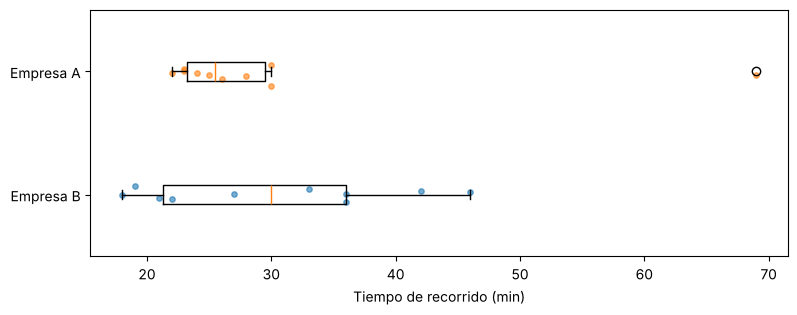

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.boxplot([B, A], vert=False, tick_labels=['Empresa B', 'Empresa A'], whis=1.5)
rng = np.random.default_rng(0)
for i, x in enumerate([B, A], start=1):
    ax.scatter(x, rng.normal(i, 0.05, len(x)), s=15, alpha=0.6)
ax.set_xlabel('Tiempo de recorrido (min)')
plt.show()

**Nota:** `plt.boxplot` calcula los cuartiles con otro método, así que con 10 datos la caja puede diferir un poco de la que dibujamos a mano.

In [13]:
# Media ± s frente a mediana y RIC
res = pd.DataFrame({'media': t.mean(), 's': t.std(),
                    'mediana': [resumen_caja(A)['Mediana'], resumen_caja(B)['Mediana']],
                    'Q1': [resumen_caja(A)['Q1'], resumen_caja(B)['Q1']],
                    'Q3': [resumen_caja(A)['Q3'], resumen_caja(B)['Q3']]}, index=['A', 'B'])
res['media - s'] = res['media'] - res['s']; res['media + s'] = res['media'] + res['s']
res.round(1)

,media,s,mediana,Q1,Q3,media - s,media + s
A,30.0,14.0,25.5,23.0,30.0,16.0,44.0
B,30.0,10.0,30.0,21.0,36.0,20.0,40.0


## Reto 4 · Decidir

In [14]:
for nombre, x in [('A', A), ('B', B)]:
    v = np.sort(x)
    p90 = v[8]                      # 9 de cada 10 viajes tardan como máximo esto
    salida = 7 * 60 - p90           # minutos desde medianoche para llegar a las 7:00
    print(f'{nombre}: días con más de 30 min = {(x > 30).sum()} | 9 de 10 viajes <= {p90} min '
          f'| salir a las {salida // 60}:{salida % 60:02d}')

A: días con más de 30 min = 1 | 9 de 10 viajes <= 30 min | salir a las 6:30
B: días con más de 30 min = 5 | 9 de 10 viajes <= 42 min | salir a las 6:18


## Caso integrador
| Pregunta | Respuesta |
|---|---|
| Empresa | A, con la condición de explicar el día 7 y garantizar un bus de reemplazo |
| Parejas | A: mediana 25,5 y RIC 7 (+ atípico 69). B: media 30 ± 10 |
| Horario | A: 6:30. B: 6:18 |
| Gráficos | Serie día a día y cajas con puntos |

In [15]:
t.describe().round(2)

,count,mean,std,min,25%,50%,75%,max
empresa,,,,,,,,
A,10.0,30.0,14.0,22.0,23.25,25.5,29.5,69.0
B,10.0,30.0,10.0,18.0,21.25,30.0,36.0,46.0
